# Titanic 泰坦尼克号生存数据分析
**项目目标**：探索泰坦尼克号乘客数据，分析性别、客舱等级、年龄等因素对生存率的影响。
**数据来源**：Kaggle - Titanic Dataset

# 1.1 载入数据
数据集下载 https://www.kaggle.com/c/titanic/overview

In [ ]:
#载入包
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.pyplot import title

In [178]:
#加载数据
df = pd.read_csv('train.csv')
print("数据形状:", df.shape)

数据形状: (891, 12)


## 1. 数据概览与缺失值检查
查看数据的基本信息，找出包含缺失值的列。


In [11]:
#查看数据基本信息
df.info()
#查看数据缺失值
print('-'*20)
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
--------------------


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
# 查看每列缺失值数量和占比
missing=df.isnull().sum()
missing_pct=(missing/len(df))*100

#拼成一个新的dataframe
missing_df=pd.DataFrame({'缺失数量':missing,'缺失占比%':missing_pct.round(2)})

missing_df[missing_df['缺失数量'] > 0]

,缺失数量,缺失占比%
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


**发现**：
- 数据集共有 891 行。
- `Age` 列有 177 个缺失值，`Cabin` 列有 687 个缺失值，`Embarked` 列有 2 个缺失值。

## 2. 数据清洗
- 删除缺失严重的 `Cabin` 列。
- 用中位数填充 `Age`。
- 用众数填充 `Embarked`。

In [18]:
#用中位数填充Age
df['Age']=df['Age'].fillna(df['Age'].median())
#用众数填充Embarked
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])
#删除缺失严重的Cabin列
df=df.drop('Cabin',axis=1)

In [31]:
# 验证是否还有缺失值
print("清洗后的缺失值情况：")
df.isnull().sum()


清洗后的缺失值情况：


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

# 3. 数据可视化与洞察

## 3.1性别与生存率的关系

[Text(0, 0, '74.2%'), Text(0, 0, '18.9%')]

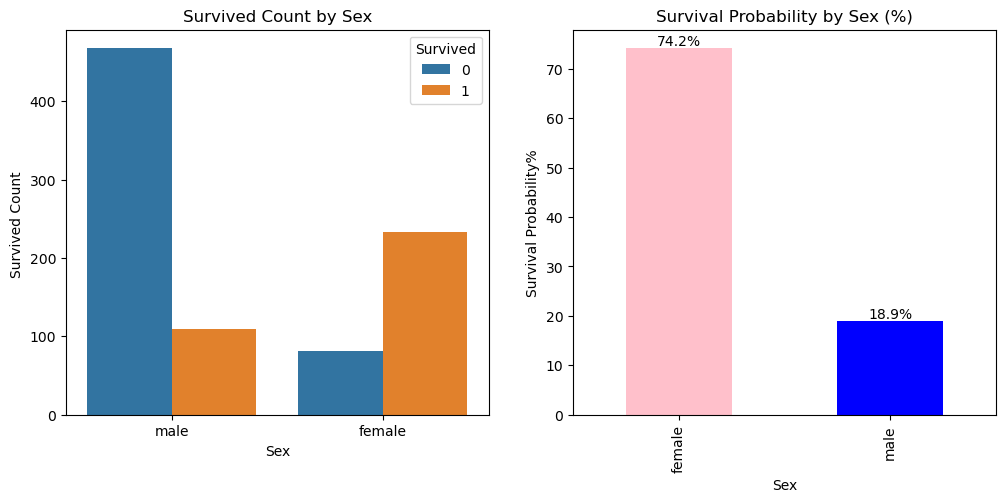

In [125]:
# === 性别与存活 ===
#创建两个画布
fig, axes = plt.subplots(1, 2, figsize=(12, 5))# 创建一个画布（figure），里面包含 1 行 2 列、共 2 个子图（axes）。

#男女存活人数对比
#countplot可以帮我们统计每个类别出现了多少次。
sns.countplot(x='Sex', hue='Survived', data=df,ax=axes[0]) #hue每种性别再按照生还情况区分颜色
axes[0].set_title('Survived Count by Sex')
axes[0].set_ylabel('Survived Count ')

#男女生存率对比
#计算出生存率
sex_Survived=df.groupby('Sex')['Survived'].mean()*100
sex_Survived.plot(kind='bar',ax=axes[1],color=['pink','blue'])
axes[1].set_title('Survival Probability by Sex (%)')
axes[1].set_ylabel('Survival Probability%')

#在柱子上标记数值
axes[1].bar_label(axes[1].containers[0], fmt='%.1f%%')

In [107]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


## 3.2 客舱等级与存活的关系

[Text(0, 0, '63.0%'), Text(0, 0, '47.3%'), Text(0, 0, '24.2%')]

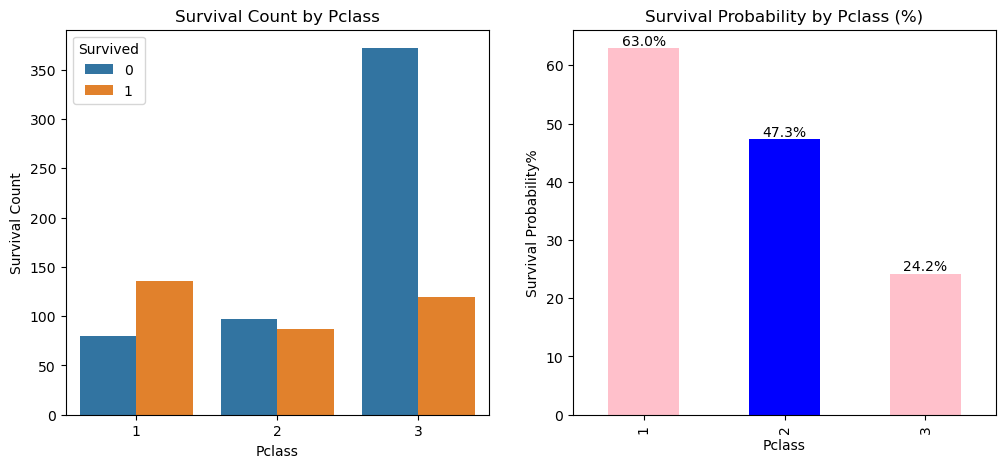

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

#客舱人数存活对比
sns.countplot(data=df,x='Pclass',hue='Survived',ax=axes[0]) # hue:每一项按什么区分
axes[0].set_title('Survival Count by Pclass')
axes[0].set_ylabel('Survival Count')

#各个客舱存活率
pclass_Survived=df.groupby('Pclass')['Survived'].mean()*100
pclass_Survived.plot(kind='bar',ax=axes[1],color=['pink','blue'])
axes[1].set_title('Survival Probability by Pclass (%)')
axes[1].set_ylabel('Survival Probability%')

#在柱子上标记数值
axes[1].bar_label(axes[1].containers[0], fmt='%.1f%%')

## 3.3 票价与存活的关系

<Axes: xlabel='Survived', ylabel='Fare'>

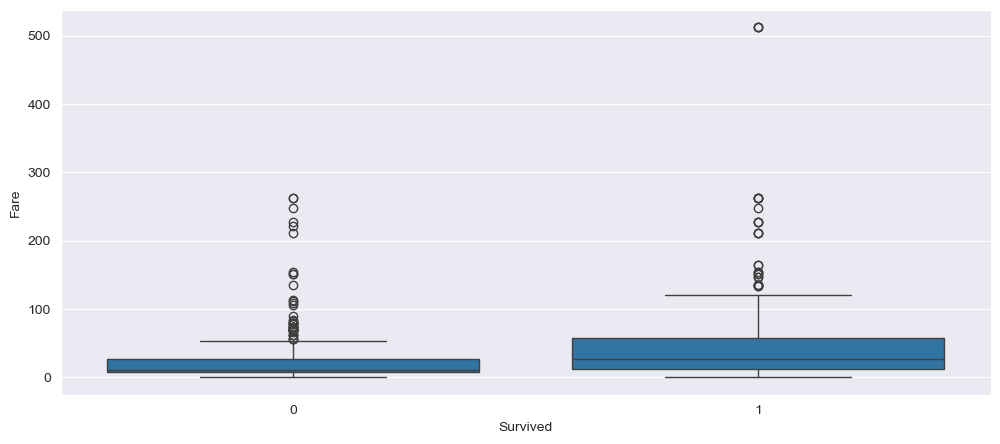

In [134]:
fig=plt.subplots( figsize=(12, 5))
#使用箱线图
sns.boxplot(data=df,x='Survived',y='Fare')

## 3.4 年龄与存活的关系

Text(0, 0.5, 'Age')

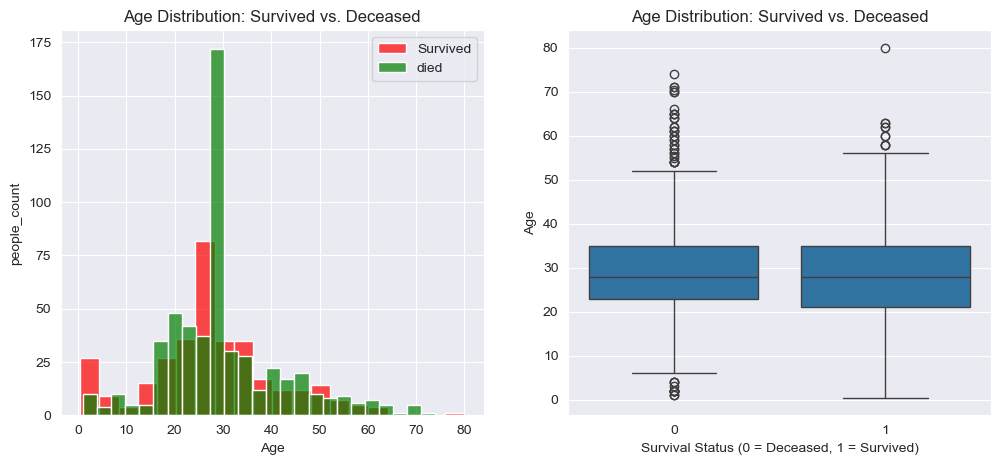

In [176]:
# === 年龄与存活 ===
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左图：存活者 vs 死亡者的年龄分布(直方图)
df_survived=df[df['Survived']==1]
df_died=df[df['Survived']==0]

#df_survived['Age'].plot(kind='hist',ax=axes[0],color='r',alpha=0.7,label='Survived')
#df_died['Age'].plot(kind='hist',ax=axes[0],color='green',alpha=0.7,label='died')
sns.histplot(data=df_survived['Age'],ax=axes[0],color='r',alpha=0.7,label='Survived')
sns.histplot(data=df_died['Age'],ax=axes[0],color='green',alpha=0.7,label='died')

axes[0].set_title('Age Distribution: Survived vs. Deceased')
axes[0].set_ylabel('people_count')
axes[0].legend()


# 右图：箱线图
sns.boxplot(data=df,x='Survived',y='Age',ax=axes[1])
axes[1].set_title('Age Distribution: Survived vs. Deceased')
axes[1].set_xlabel('Survival Status (0 = Deceased, 1 = Survived)')
axes[1].set_ylabel('Age')
